<a href="https://colab.research.google.com/github/leeknnn/viktoriiashkorubska-41/blob/master/lab_work_7/lab_work_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

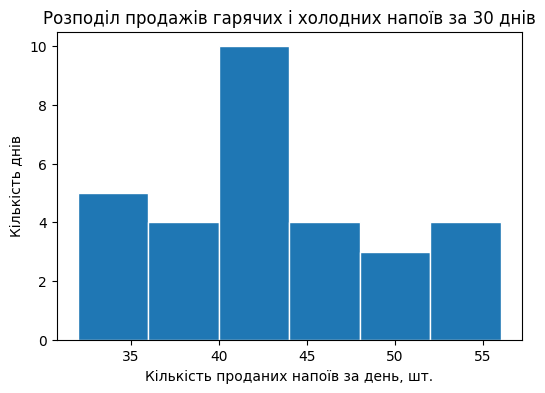

/tmp/ipykernel_1568/2396715941.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=["Будній", "Вихідний"])


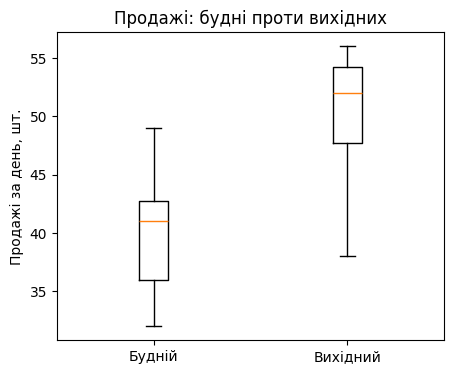

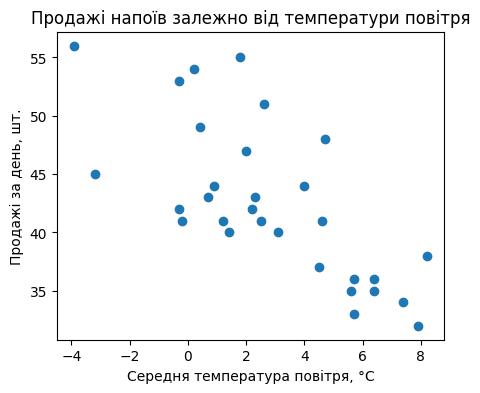

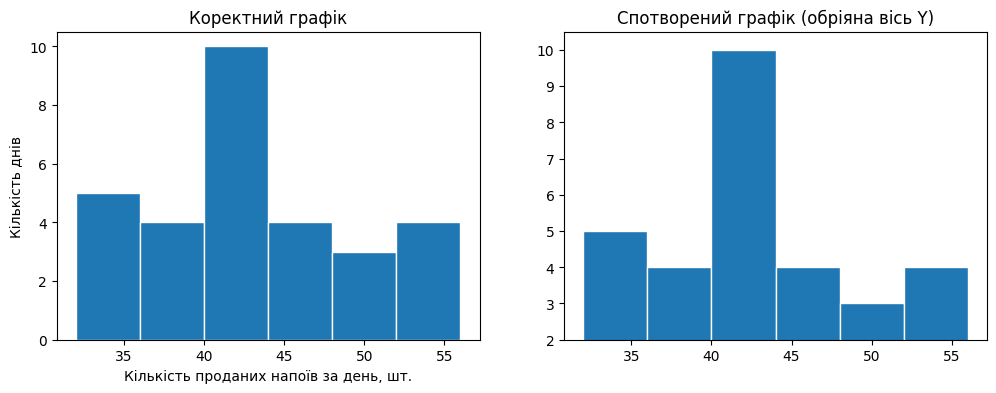

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(1)
days = np.arange(1, 31)
weekend = np.isin(days % 7, [6, 0])

temperature = np.round(np.random.normal(3, 3, size=30), 1)

sales = np.round(
    40 + weekend * 8 - (temperature - 3) * 1.2 + np.random.normal(0, 3, size=30)
).astype(int)

df_kiosk = pd.DataFrame({
    "день": days,
    "вихідний": weekend,
    "температура": temperature,
    "продажі": sales
})

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df_kiosk["продажі"], bins=6, edgecolor="white")
ax.set_xlabel("Кількість проданих напоїв за день, шт.")
ax.set_ylabel("Кількість днів")
ax.set_title("Розподіл продажів гарячих і холодних напоїв за 30 днів")
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
groups = [df_kiosk.loc[~df_kiosk["вихідний"], "продажі"], df_kiosk.loc[df_kiosk["вихідний"], "продажі"]]
ax.boxplot(groups, labels=["Будній", "Вихідний"])
ax.set_ylabel("Продажі за день, шт.")
ax.set_title("Продажі: будні проти вихідних")
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(df_kiosk["температура"], df_kiosk["продажі"])
ax.set_xlabel("Середня температура повітря, °C")
ax.set_ylabel("Продажі за день, шт.")
ax.set_title("Продажі напоїв залежно від температури повітря")
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(df_kiosk["продажі"], bins=6, edgecolor="white")
ax1.set_xlabel("Кількість проданих напоїв за день, шт.")
ax1.set_ylabel("Кількість днів")
ax1.set_title("Коректний графік")

ax2.hist(df_kiosk["продажі"], bins=6, edgecolor="white")
ax2.set_ylim(bottom=df_kiosk["продажі"].value_counts().max() - 2)
ax2.set_title("Спотворений графік (обріяна вісь Y)")
plt.show()

## Відповіді на контрольні питання

1. **Чому обрізана вісь Y на стовпчиковій або гістограмній діаграмі перебільшує різницю між категоріями, хоча підписані числа залишаються правильними?**
   - Людське око оцінює не лише абсолютні цифри, а й відносну висоту стовпчиків або площу фігур. Коли вісь Y починається не з нуля, нульова база відліку втрачається, через що незначні коливання чи невеликі різниці сприймаються зоровим апаратом як карколомні перепади та багаторазові переваги.

2. **Наведіть приклад, коли лінійний графік (з'єднання точок лінією) буде методологічною помилкою для категоріальних даних, і поясніть чому — з посиланням на шкали вимірювання.**
   - Лінійний графік передбачає неперервність або часову послідовність по осі X (наприклад, шкала інтервалів чи відношень для часу або температури). Якщо застосувати його для номінальної шкали (наприклад, назви міст чи групи крові), з'єднання точок лінією створюватиме фальшиву ілюзію математичного переходу чи тренду між незалежними категоріями, де порядок розташування на осі є довільним.

3. **Чому підписи осей, одиниці вимірювання і заголовок — не оздоблення графіка, а частина твердження, яке він робить?**
   - Без чіткого заголовка, підписаних осей та зазначення одиниць вимірювання візуалізація є набором абстрактних геометричних фігур, які кожен може інтерпретувати по-різному. Саме текстовий супровід задає контекст, масштаб і точний сенс даних, перетворюючи малюнок на однозначне аналітичне твердження.

4. **Що таке chartjunk (наприклад, 3D-ефект на звичайній стовпчиковій діаграмі) і чому він шкодить, а не прикрашає сприйняття графіка?**
   - Chartjunk це надлишкові візуальні елементи (зайві об'єми, 3D-ефекти, текстури, фонові картинки), які не нестять корисної інформації про дані. Вони перевантажують увагу глядача, створюють оптичні спотворення (коли об'єм у 3D заважає точно зчитати висоту стовпчика за шкалою) і заважають сприймати суть аналітичного повідомлення.